# House Stage 1 regression

The formula is the model: `run_ols(formula, train_years, eval_years)` fits it with `smf.ols(formula, data=train).fit()` and returns the native statsmodels result as `result.model`. It is the same function as `python -m experiments.house.run` (see `experiments/house/run.py`). Shared data prep, validation, and metrics are in `experiments/house/evaluation.py`, and saved runs in `experiments/house/tracking.py`. Holdout years: `src/house/regression/config.py`. Columns: `src/house/regression/schema.py`.
Build the predictors and targets first: `python data-processing/house/house_features.py` (`modeling.csv`) and `python data-processing/house/house_targets.py` (`targets.csv`).
Imputed targets are never trained on or scored: they were built from partisan lean, so scoring against them would reward a model for agreeing with it. Evaluation scores valid targets only (observed, non-imputed, of an eligible race type) and competitive subsets of them, per eval year; see `experiments/house/evaluation.py`. Every left-out row is listed with its reason in `result.excluded`. Nothing is saved unless you ask (`save=True` or `tracking.save_run`).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The repository root is the first folder up from here that holds pyproject.toml, so this works at any depth
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))  # repository root, for experiments.house
import house.regression as hr  # hr.<Tab> lists everything; names are in src/house/regression/__init__.py
from experiments.house import evaluation, tracking
from experiments.house.run import run_ols

In [2]:
import warnings

with warnings.catch_warnings(action="ignore"):  # loading warns with the same summaries printed below
    predictors = hr.load_predictors()  # data/processed/house/modeling.csv, every year (2006-2026)
    targets = hr.load_targets()        # data/processed/house/targets.csv, every year (2006-2024)
print(hr.validate_schema(predictors).summary())  # .issues lists every affected key

In [3]:
print(hr.validate_schema(targets, schema=hr.TARGETS_SCHEMA).summary())

In [4]:
FORMULA = "adj_margin_2p_norm ~ gen_margin_raw + partisan_lean + inc_signed"
TRAIN_YEARS = [2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020]
EVAL_YEARS = [2022]     # scored against actual targets
PREDICT_YEARS = []      # predicted only, no metrics, e.g. [2026] for a forecast
USE_HOLDOUT = False     # True allows HOLDOUT_YEARS (2024) in training, evaluation, or prediction
REQUIRE_COMPLETE = []   # extra columns a row must have, so runs with different formulas share rows
# Evaluation only (training is unaffected): observed, non-imputed targets of these race types are scored ("valid")
EVAL_RACE_TYPES = ["dr", "dr_multi", "dr_jungle", "dr_rcv", "dr_writein"]
# Competitive subsets of the valid targets: name -> (column, threshold); a row is in one when abs(column) <= threshold.
# column is a column name or arithmetic of them, from the targets or the predictors
EX_ANTE_THRESHOLD = 10   # points: any non-negative int or float, e.g. 5, 7, or 7.5
EX_POST_THRESHOLD = 7.5
COMPETITIVE = {
    # expected margin under uniform swing: two-party lean (2 x cook_pvi) + eve-of-election two-party generic ballot
    "competitive_ex_ante": ("partisan_lean + gb_margin_2p_norm", EX_ANTE_THRESHOLD),
    "competitive_ex_post": ("margin_2p_norm", EX_POST_THRESHOLD),  # observed two-party margin
}

result = run_ols(
    formula=FORMULA,
    train_years=TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,  # the tables loaded above, instead of reloading per run
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=REQUIRE_COMPLETE,
    race_types=EVAL_RACE_TYPES,
    competitive=COMPETITIVE,
    name="classic_ols",
    save=False,             # True writes results/house/runs/<run_id>
)
print(tracking.describe(result))  # result.config has the raw values

estimator         ols
formula           adj_margin_2p_norm ~ gen_margin_raw + partisan_lean + inc_signed
target            adj_margin_2p_norm
name              classic_ols
train_years       2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020
eval_years        2022
predict_years     -
variables         basic_f: [gen_margin_raw, partisan_lean, inc_signed]
require_complete  -
competitive       competitive_ex_ante: abs(partisan_lean + gb_margin_2p_norm) <= 10
                  competitive_ex_post: abs(margin_2p_norm) <= 7.5
use_holdout       False (HOLDOUT_YEARS: [2024])
train             3083 rows (excluded: imputed_target 397)
eval              399 rows, 399 scored (excluded: imputed_target 36)
run_id            (unsaved)
timestamp         2026-11-02T16:54:07
git_commit        706c199 (dirty)
data_hash         49130d58940a-ef379824e59c
statsmodels       0.15.0


In [5]:
evaluation.excluded_by_year(result.excluded, max_districts=5)  # every row left out, by year and reason (None lists all)

,role,reason,n,districts
year,,,,
2006,train,imputed_target,56,"AL-05, AL-06, AL-07, AZ-06, CA-07, ... (+51)"
2008,train,imputed_target,57,"AL-01, AL-06, AL-07, AR-01, AR-02, ... (+52)"
2010,train,imputed_target,29,"AL-01, AL-04, AL-06, CA-21, CA-22, ... (+24)"
2012,train,imputed_target,45,"AL-01, AR-03, AZ-07, CA-08, CA-13, ... (+40)"
2014,train,imputed_target,77,"AL-04, AL-05, AL-07, AR-03, AZ-07, ... (+72)"
2016,train,imputed_target,64,"AL-01, AL-04, AL-07, AR-01, AR-03, ... (+59)"
2018,train,imputed_target,42,"AL-07, AZ-07, CA-05, CA-06, CA-08, ... (+37)"
2020,train,imputed_target,27,"AL-05, AL-06, AL-07, AR-01, CA-12, ... (+22)"
2022,eval,imputed_target,36,"AL-01, AL-06, AZ-08, AZ-09, CA-10, ... (+31)"


In [6]:
result.model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     adj_margin_2p_norm   R-squared:                       0.909
Model:                            OLS   Adj. R-squared:                  0.909
Method:                 Least Squares   F-statistic:                 1.027e+04
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:54:08   Log-Likelihood:                -11574.
No. Observations:                3083   AIC:                         2.316e+04
Df Residuals:                    3079   BIC:                         2.318e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -0.4833      0.227     -2.126      0.034      -0.929      -0.038
gen_margin_raw     0.8273      0.030     27.404      0.000       0.768       0.887
partisan_lean      0.8171      0.009     91.890      0.000       0.800       0.835
inc_signed        11.7178      0.277     42.255      0.000      11.174      12.262
==============================================================================
Omnibus:                      154.817   Durbin-Watson:                   1.606
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              465.142
Skew:                           0.201   Prob(JB):                    9.90e-102
Kurtosis:                       4.860   Cond. No.                         43.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [7]:
result.metrics.round(3)  # by (subset, year), then pooled ("all"); bias = mean(actual - predicted): + means Democrats outperformed

n    mae   rmse   bias  n_classified  \
subset              year                                           
valid               2022  399  6.268  7.620  0.506           399   
                    all   399  6.268  7.620  0.506           399   
competitive_ex_ante 2022   81  6.355  7.564 -0.989            81   
                    all    81  6.355  7.564 -0.989            81   
competitive_ex_post 2022   52  7.542  9.137 -0.463            52   
                    all    52  7.542  9.137 -0.463            52   

                          n_actual_tie  n_predicted_tie  missed_races  \
subset              year                                                
valid               2022             0                0            16   
                    all              0                0            16   
competitive_ex_ante 2022             0                0            15   
                    all              0                0            15   
competitive_ex_post 2022             0                0            15   
                    all              0                0            15   

                          missed_pct  accuracy_pct  precision_D_pct  \
subset              year                                              
valid               2022       4.010        95.990           95.545   
                    all        4.010        95.990           95.545   
competitive_ex_ante 2022      18.519        81.481           83.019   
                    all       18.519        81.481           83.019   
competitive_ex_post 2022      28.846        71.154           73.333   
                    all       28.846        71.154           73.333   

                          precision_R_pct  actual_D_pred_D  actual_D_pred_R  \
subset              year                                                      
valid               2022           96.447              193                7   
                    all            96.447              193                7   
competitive_ex_ante 2022           78.571               44                6   
                    all            78.571               44                6   
competitive_ex_post 2022           68.182               22                7   
                    all            68.182               22                7   

                          actual_R_pred_D  actual_R_pred_R  n_winner_conflict  
subset              year                                                       
valid               2022                9              190                  1  
                    all                 9              190                  1  
competitive_ex_ante 2022                9               22                  0  
                    all                 9               22                  0  
competitive_ex_post 2022                8               15                  1  
                    all                 8               15                  1

In [8]:
# Winner calls, in % of the classified races (ties left out): "valid" is every observed, non-imputed district
#   accuracy_pct     correct winner calls
#   precision_D_pct  of the races predicted D, the % the Democrat won
#   precision_R_pct  of the races predicted R, the % the Republican won
result.metrics[["n_classified", "accuracy_pct", "precision_D_pct", "precision_R_pct"]].round(1)

n_classified  accuracy_pct  precision_D_pct  \
subset              year                                                
valid               2022           399          96.0             95.5   
                    all            399          96.0             95.5   
competitive_ex_ante 2022            81          81.5             83.0   
                    all             81          81.5             83.0   
competitive_ex_post 2022            52          71.2             73.3   
                    all             52          71.2             73.3   

                          precision_R_pct  
subset              year                   
valid               2022             96.4  
                    all              96.4  
competitive_ex_ante 2022             78.6  
                    all              78.6  
competitive_ex_post 2022             68.2  
                    all              68.2

## Stage 1 evaluation

`result.metrics` scores the **valid** targets (a finite `adj_margin_2p_norm`, `is_imputed == False`, race type in `EVAL_RACE_TYPES`) and each `COMPETITIVE` subset of them, per eval year and pooled (`all`). An empty subset shows `n = 0` and NaN metrics.

- `residual = actual - predicted` everywhere (`result.predictions`, `result.scored`, the metrics, the reports below, and statsmodels' `result.model.resid`). `bias` is the mean residual: **positive means Democrats outperformed the forecast**, negative that Republicans did.
- Winners come from the sign of each margin. A margin of exactly 0 is a tie, not assigned to a party: such rows are left out of `n_classified`, the denominator of `missed_pct` (the percentage of classified races with the wrong predicted winner), and counted in `n_actual_tie` / `n_predicted_tie`.
- `n_winner_conflict` counts rows whose actual margin sign disagrees with `targets.winner_party`, e.g. AK-AL 2022, an RCV race the Democrat won after trailing in the first round. Classification still uses the margin sign; the rows are flagged in `result.scored["winner_conflict"]`.

`result.coverage` accounts for every eval-year district: excluded by reason (first match wins: `missing_target`, `imputed_target`, `race_type:<type>`, `no_prediction`), then `n_valid` and the size of each competitive subset.

In [9]:
result.coverage  # eval districts by exclusion reason, then the scored subsets

,n_districts,missing_target,imputed_target,no_prediction,n_valid,competitive_ex_ante,competitive_ex_ante_undetermined,competitive_ex_post,competitive_ex_post_undetermined
year,,,,,,,,,
2022,435,0,36,0,399,81,0,52,0
all,435,0,36,0,399,81,0,52,0


In [10]:
# actual (rows) by predicted (columns) winner, pooled over the eval years; ties are left out (counted in metrics).
# As counts, then as a percentage of each subset's classified races (the off-diagonal cells add up to missed_pct)
SUBSETS = ["valid", *COMPETITIVE]
display(pd.concat({subset: evaluation.confusion_matrix(result.scored, subset=subset) for subset in SUBSETS}, axis=1))
display(pd.concat({subset: evaluation.confusion_matrix(result.scored, subset=subset, percent=True)
                   for subset in SUBSETS}, axis=1).round(1))

valid      competitive_ex_ante     competitive_ex_post    
predicted     D    R                   D   R                   D   R
actual                                                              
D           193    7                  44   6                  22   7
R             9  190                   9  22                   8  15

valid       competitive_ex_ante       competitive_ex_post      
predicted     D     R                   D     R                   D     R
actual                                                                   
D          48.4   1.8                54.3   7.4                42.3  13.5
R           2.3  47.6                11.1  27.2                15.4  28.8

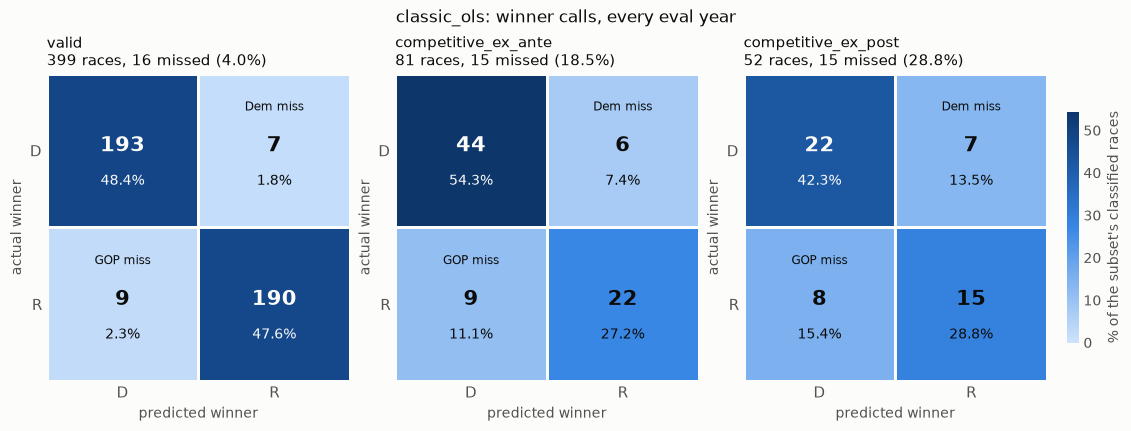

In [11]:
from matplotlib.colors import LinearSegmentedColormap

# Sequential blue ramp (light = few races, dark = many), on one shared % scale so the panels compare directly
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
SURFACE, INK, INK_SECONDARY = "#fcfcfb", "#0b0b0b", "#52514e"
MISS_LABELS = {("D", "R"): "Dem miss", ("R", "D"): "GOP miss"}  # (actual, predicted)
CONFUSION_YEAR = None  # one eval year, e.g. 2022; None pools every eval year


def plot_confusion(scored, subsets, year=None):
    """One heatmap per subset: actual (rows) by predicted (columns) winner, each cell's count and its % of the
    subset's classified races (ties left out, as in metrics)."""
    counts = {s: evaluation.confusion_matrix(scored, subset=s, year=year) for s in subsets}
    shares = {s: evaluation.confusion_matrix(scored, subset=s, year=year, percent=True) for s in subsets}
    vmax = pd.concat(shares.values()).max().max()
    vmax = vmax if vmax > 0 else 100  # every subset empty: any scale
    fig, axes = plt.subplots(1, len(subsets), figsize=(3.4 * len(subsets) + 1, 4.2), layout="constrained",
                             facecolor=SURFACE, squeeze=False)
    for ax, subset in zip(axes[0], subsets):
        count, share = counts[subset], shares[subset]
        mesh = ax.pcolormesh(share.to_numpy(), cmap=BLUES, vmin=0, vmax=vmax, edgecolors=SURFACE, linewidth=2)
        for i, actual in enumerate(count.index):
            for j, predicted in enumerate(count.columns):
                pct = share.iloc[i, j]
                r, g, b, _ = BLUES(0 if pd.isna(pct) else pct / vmax)
                ink = SURFACE if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.45 else INK  # readable on the fill
                ax.text(j + 0.5, i + 0.47, f"{count.iloc[i, j]}", ha="center", va="center", fontsize=15,
                        fontweight="bold", color=ink)
                ax.text(j + 0.5, i + 0.70, "-" if pd.isna(pct) else f"{pct:.1f}%", ha="center", va="center",
                        fontsize=10, color=ink)
                if (actual, predicted) in MISS_LABELS:
                    ax.text(j + 0.5, i + 0.22, MISS_LABELS[actual, predicted], ha="center", va="center",
                            fontsize=8.5, color=ink)
        n = int(count.to_numpy().sum())
        missed = int(count.loc["D", "R"] + count.loc["R", "D"])
        ax.set_title(f"{subset}\n{n} races, {missed} missed ({100 * missed / n:.1f}%)" if n
                     else f"{subset}\nno classified races", loc="left", fontsize=10.5, color=INK)
        ax.set_xticks([0.5, 1.5], ["D", "R"])
        ax.set_yticks([0.5, 1.5], ["D", "R"])
        ax.invert_yaxis()  # actual D on top
        ax.set_xlabel("predicted winner", color=INK_SECONDARY)
        ax.set_ylabel("actual winner", color=INK_SECONDARY)
        ax.tick_params(length=0, colors=INK_SECONDARY, labelsize=11)
        ax.spines[:].set_visible(False)
    colorbar = fig.colorbar(mesh, ax=axes[0], shrink=0.75, pad=0.02)
    colorbar.set_label("% of the subset's classified races", color=INK_SECONDARY)
    colorbar.ax.tick_params(length=0, colors=INK_SECONDARY)
    colorbar.outline.set_visible(False)
    fig.suptitle(f"{result.config['name']}: winner calls, " + (str(year) if year else "every eval year"),
                 fontsize=12, color=INK)
    plt.show()


plot_confusion(result.scored, subsets=["valid", *COMPETITIVE], year=CONFUSION_YEAR)

In [12]:
N_EXAMPLES = 10
EXAMPLE_SUBSET = "competitive_ex_ante"
EXAMPLE_SEED = 0          # a random sample, reproducible: not chosen by how well the model did
EXAMPLE_DISTRICTS = None  # or explicit (year, state, district) keys in EXAMPLE_SUBSET, e.g. [(2022, "AZ", 6)]

evaluation.competitive_examples(result.scored, subset=EXAMPLE_SUBSET, n=N_EXAMPLES, seed=EXAMPLE_SEED,
                                districts=EXAMPLE_DISTRICTS)

,year,state,district,actual_margin,predicted_margin,residual,abs_residual,actual_winner,predicted_winner,correct_winner,outcome,race_type,winner_party,winner_conflict,partisan_lean + gb_margin_2p_norm,competitive_ex_ante,margin_2p_norm,competitive_ex_post
0,2022,CO,7,15.323465,4.867852,10.455613,10.455613,D,D,True,correct,dr,D,False,6.466535,True,15.323465,False
1,2022,IA,1,-6.808469,-18.910271,12.101802,12.101802,R,R,True,correct,dr,R,False,-8.293465,True,-6.808469,True
2,2022,IL,11,12.906021,18.889901,-5.983879,5.983879,D,D,True,correct,dr,D,False,9.286535,True,12.906021,False
3,2022,IL,13,13.233826,4.132470,9.101356,9.101356,D,D,True,correct,dr,D,False,5.566535,True,13.233826,False
4,2022,IN,1,5.682042,14.755416,-9.073374,9.073374,D,D,True,correct,dr,D,False,4.226535,True,5.682042,True
5,2022,NV,4,4.830395,14.461263,-9.630869,9.630869,D,D,True,correct,dr,D,False,3.866535,True,4.830395,True
6,2022,NY,2,-21.451525,-18.763194,-2.688330,2.688330,R,R,True,correct,dr,R,False,-8.113465,True,-21.451525,False
7,2022,NY,22,-0.980045,0.390190,-1.370235,1.370235,R,D,False,gop_miss,dr,R,False,0.986535,True,-0.980045,True
8,2022,PA,7,1.966041,6.764260,-4.798218,4.798218,D,D,True,correct,dr,D,False,-5.553465,True,1.966041,True
9,2022,RI,2,3.819325,5.439816,-1.620491,1.620491,D,D,True,correct,dr,D,False,7.166535,True,3.819325,True


In [13]:
N_WORST = 10

evaluation.worst_misses(result.scored, n=N_WORST)  # every valid target, largest abs_residual first

,year,state,district,actual_margin,predicted_margin,residual,abs_residual,actual_winner,predicted_winner,correct_winner,outcome,race_type,winner_party,winner_conflict,partisan_lean + gb_margin_2p_norm,competitive_ex_ante,margin_2p_norm,competitive_ex_post
0,2022,CO,3,-0.166905,-24.744306,24.577401,24.577401,R,R,True,correct,dr,R,False,-15.433465,False,-0.166905,True
1,2022,MD,1,-11.587650,-30.529315,18.941665,18.941665,R,R,True,correct,dr,R,False,-22.513465,False,-11.587650,False
2,2022,MD,4,80.651467,63.077465,17.574002,17.574002,D,D,True,correct,dr,D,False,77.706535,False,80.651467,False
3,2022,CA,38,16.183144,33.646577,-17.463433,17.463433,D,D,True,correct,dr,D,False,27.346535,False,16.183144,False
4,2022,NJ,8,51.698778,34.381205,17.317573,17.317573,D,D,True,correct,dr,D,False,42.586535,False,51.698778,False
5,2022,CA,35,14.729712,31.996051,-17.266339,17.266339,D,D,True,correct,dr,D,False,25.326535,False,14.729712,False
6,2022,WV,2,-31.137267,-48.374598,17.237331,17.237331,R,R,True,correct,dr,R,False,-44.353465,False,-31.137267,False
7,2022,GA,14,-31.729314,-48.783144,17.053830,17.053830,R,R,True,correct,dr,R,False,-44.853465,False,-31.729314,False
8,2022,FL,9,7.270912,23.383905,-16.112992,16.112992,D,D,True,correct,dr,D,False,14.786535,False,7.270912,True
9,2022,CA,21,8.357541,24.446124,-16.088583,16.088583,D,D,True,correct,dr,D,False,16.086535,False,8.357541,False


In [14]:
for subset in COMPETITIVE:  # the worst misses within each competitive subset
    print(subset)
    display(evaluation.worst_misses(result.scored, n=N_WORST, subset=subset))

competitive_ex_ante


,year,state,district,actual_margin,predicted_margin,residual,abs_residual,actual_winner,predicted_winner,correct_winner,outcome,race_type,winner_party,winner_conflict,partisan_lean + gb_margin_2p_norm,competitive_ex_ante,margin_2p_norm,competitive_ex_post
0,2022,OH,1,5.517516,-10.347150,15.864666,15.864666,D,R,False,dem_miss,dr,D,False,2.186535,True,5.517516,True
1,2022,AZ,1,-0.883874,-16.491679,15.607806,15.607806,R,R,True,correct,dr,R,False,-5.333465,True,-0.883874,True
2,2022,NY,17,-0.637970,14.935177,-15.573146,15.573146,R,D,False,gop_miss,dr,R,False,4.446535,True,-0.637970,True
3,2022,CT,5,0.192588,14.575656,-14.383069,14.383069,D,D,True,correct,dr,D,False,4.006535,True,0.192588,True
4,2022,CA,41,-4.690709,-18.387332,13.696623,13.696623,R,R,True,correct,dr,R,False,-7.653465,True,-4.690709,True
5,2022,MI,3,13.332602,0.602634,12.729969,12.729969,D,D,True,correct,dr,D,False,1.246535,True,13.332602,False
6,2022,CA,47,3.430647,15.588850,-12.158203,12.158203,D,D,True,correct,dr,D,False,5.246535,True,3.430647,True
7,2022,NM,2,0.727139,-11.376685,12.103824,12.103824,D,R,False,dem_miss,dr_multi,D,False,0.926535,True,0.727139,True
8,2022,IA,1,-6.808469,-18.910271,12.101802,12.101802,R,R,True,correct,dr,R,False,-8.293465,True,-6.808469,True
9,2022,IA,2,-8.248748,-20.201276,11.952528,11.952528,R,R,True,correct,dr,R,False,-9.873465,True,-8.248748,False


competitive_ex_post


,year,state,district,actual_margin,predicted_margin,residual,abs_residual,actual_winner,predicted_winner,correct_winner,outcome,race_type,winner_party,winner_conflict,partisan_lean + gb_margin_2p_norm,competitive_ex_ante,margin_2p_norm,competitive_ex_post
0,2022,CO,3,-0.166905,-24.744306,24.577401,24.577401,R,R,True,correct,dr,R,False,-15.433465,False,-0.166905,True
1,2022,FL,9,7.270912,23.383905,-16.112992,16.112992,D,D,True,correct,dr,D,False,14.786535,False,7.270912,True
2,2022,OH,1,5.517516,-10.347150,15.864666,15.864666,D,R,False,dem_miss,dr,D,False,2.186535,True,5.517516,True
3,2022,AZ,1,-0.883874,-16.491679,15.607806,15.607806,R,R,True,correct,dr,R,False,-5.333465,True,-0.883874,True
4,2022,NY,17,-0.637970,14.935177,-15.573146,15.573146,R,D,False,gop_miss,dr,R,False,4.446535,True,-0.637970,True
5,2022,CT,5,0.192588,14.575656,-14.383069,14.383069,D,D,True,correct,dr,D,False,4.006535,True,0.192588,True
6,2022,CA,41,-4.690709,-18.387332,13.696623,13.696623,R,R,True,correct,dr,R,False,-7.653465,True,-4.690709,True
7,2022,VA,10,6.510177,19.903094,-13.392917,13.392917,D,D,True,correct,dr,D,False,10.526535,False,6.510177,True
8,2022,CA,47,3.430647,15.588850,-12.158203,12.158203,D,D,True,correct,dr,D,False,5.246535,True,3.430647,True
9,2022,NM,2,0.727139,-11.376685,12.103824,12.103824,D,R,False,dem_miss,dr_multi,D,False,0.926535,True,0.727139,True


### Competitive races by outcome

For each competitive subset: the races predicted correctly, the **Dem misses** (predicted R, the Democrat won), and the **GOP misses** (predicted D, the Republican won). States are in alphabetical order, and within each state the closest actual margin (`abs(adj_margin_2p_norm)`) comes first. The party in parentheses is the actual winner.

In [15]:
for subset in COMPETITIVE:
    print(evaluation.outcome_report(result.scored, subset=subset), end="\n\n")

competitive_ex_ante: 81 districts; residual = actual - predicted

===== 2022 =====

PREDICTED CORRECTLY (66)
* AZ-01 (R): predicted margin: -16.49, actual: -0.88, residual: +15.61
* AZ-06 (R): predicted margin: -5.84, actual: -1.48, residual: +4.36
* AZ-04 (D): predicted margin: +13.94, actual: +12.21, residual: -1.73
* CA-22 (R): predicted margin: -4.92, actual: -3.05, residual: +1.88
* CA-47 (D): predicted margin: +15.59, actual: +3.43, residual: -12.16
* CA-41 (R): predicted margin: -18.39, actual: -4.69, residual: +13.70
* CA-45 (R): predicted margin: -9.71, actual: -4.83, residual: +4.88
* CA-49 (D): predicted margin: +15.36, actual: +5.26, residual: -10.10
* CA-27 (R): predicted margin: -6.59, actual: -6.48, residual: +0.11
* CA-03 (R): predicted margin: -7.57, actual: -7.30, residual: +0.27
* CA-09 (D): predicted margin: +17.71, actual: +9.63, residual: -8.08
* CA-40 (R): predicted margin: -16.25, actual: -13.67, residual: +2.58
* CO-07 (D): predicted margin: +4.87, actual: +15.

In [16]:
N_STATES = 15

# every valid district by state, pooled over the eval years, worst |mean residual| first (residual = actual - predicted:
# + means Democrats outperformed the forecast). A state with few districts can rank high on one race: read
# mean_residual with n_districts
evaluation.state_summary(result.scored, subsets=COMPETITIVE).head(N_STATES).round(2)

,n_districts,mean_residual,mean_abs_residual,n_missed,n_dem_miss,n_gop_miss,pct_missed,n_competitive_ex_ante,missed_competitive_ex_ante,pct_missed_competitive_ex_ante,n_competitive_ex_post,missed_competitive_ex_post,pct_missed_competitive_ex_post
state,,,,,,,,,,,,,
VT,1,14.58,14.58,0,0,0,0.0,0,0,NaN,0,0,NaN
WV,2,14.36,14.36,0,0,0,0.0,0,0,NaN,0,0,NaN
HI,2,10.82,10.82,0,0,0,0.0,0,0,NaN,0,0,NaN
KS,4,8.97,8.97,0,0,0,0.0,1,0,0.0,0,0,NaN
DE,1,-8.54,8.54,0,0,0,0.0,0,0,NaN,0,0,NaN
CO,8,8.51,8.84,1,1,0,12.5,2,1,50.0,2,1,50.0
MT,1,8.38,8.38,0,0,0,0.0,0,0,NaN,1,0,0.0
MS,4,-7.00,7.00,0,0,0,0.0,0,0,NaN,0,0,NaN
CT,5,-6.98,8.36,0,0,0,0.0,2,0,0.0,1,0,0.0


## Prediction diagnostics

The evaluation rows of `result.predictions` (`role == "eval"`, here the 2022 districts), with an observed target. Modeled imputations (uncontested and similar races, see `MODELED_IMPUTATION_METHODS`) are excluded and listed in `result.excluded`; jungle and first-round RCV races are observed, so they are kept. Each row has:

- `prediction`: the model's predicted margin, D positive, in points.
- `actual`: the target, `adj_margin_2p_norm`.
- `residual` = `actual - prediction`, the statsmodels convention (`result.model.resid`) and the sign of the metrics' `bias`: a positive residual means the Democrat outperformed the forecast.

**Reading the two cells below:**

- The residual summary describes the scored rows.
- The scatter plots actual against predicted. Points on the grey diagonal are exact; points above it have a positive residual (the Democrat outperformed the forecast).

**Out-of-range predictions:** OLS is unbounded, so a prediction can fall outside the ±100 a margin can take, typically in the safest seats. Predictions are never clipped here, so the backtest scores the raw model. An evaluation or prediction row beyond ±100 raises a warning (in-sample fitted values aren't flagged).

**Clipping at forecast time:** clipping to ±100 belongs to the forecast step, as one visible line. Every actual margin lies within ±100, so clipping can only move a prediction closer to it. The unclipped MAE and RMSE above are therefore a slight upper bound on the clipped forecast's error.

In [17]:
scored = result.predictions[result.predictions["role"] == "eval"].dropna(subset=["actual"])
scored["residual"].describe()  # residual = actual - prediction

count    399.000000
mean       0.506234
std        7.612731
min      -17.463433
25%       -4.990907
50%        0.681518
75%        5.821037
max       24.577401
Name: residual, dtype: float64

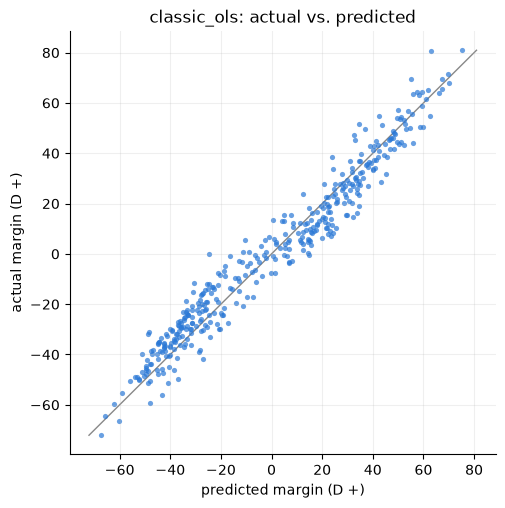

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(scored["prediction"], scored["actual"], s=14, color="#2a78d6", alpha=0.7, linewidths=0)
lim = [scored[["prediction", "actual"]].min().min(), scored[["prediction", "actual"]].max().max()]
ax.plot(lim, lim, color="#888", lw=1, zorder=0)
ax.set(xlabel="predicted margin (D +)", ylabel="actual margin (D +)", title=f"{result.config['name']}: actual vs. predicted")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Ablations and variants (not saved)

Each block is a dict of formulas whose **first entry is the base** every other run is compared with (`change`). `require_complete` is every predictor column any formula in the dict uses (`evaluation.shared_columns`), so all runs fit and score the same rows (`same rows` ✓): a metric change is a modeling change, not a sample change.

The table shows each subset in `COMPARE_SUBSETS`: every valid (observed, non-imputed) district, then the competitive subsets as defined by `COMPETITIVE` in the settings cell above. For each: `n`, MAE, RMSE, `bias` (mean residual, actual − predicted: **+ means Democrats outperformed the forecast**), and `accuracy_pct` (% correct winner calls). The best value per subset is in bold.

In [19]:
TARGET = "adj_margin_2p_norm"
COMPARE_SUBSETS = ["valid", *COMPETITIVE]  # the subsets each comparison table shows

ABLATIONS = {
    "classic_ols": FORMULA,  # the base
    "no_gen_margin_raw": f"{TARGET} ~ partisan_lean + inc_signed",
    "no_partisan_lean": f"{TARGET} ~ gen_margin_raw + inc_signed",
    "no_inc_signed": f"{TARGET} ~ gen_margin_raw + partisan_lean",
    "plus_acs": FORMULA + " + college + hispanic",
    "lean_x_inc": FORMULA + " + partisan_lean:inc_signed",
    "inc_categorical": f"{TARGET} ~ gen_margin_raw + partisan_lean + C(inc_signed)",
}
ABLATION_SHARED_COLUMNS = evaluation.shared_columns(formulas=ABLATIONS.values(), columns=predictors.columns)

ablations = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=ABLATION_SHARED_COLUMNS,
        race_types=EVAL_RACE_TYPES,
        competitive=COMPETITIVE,
        name=name,
        save=False,
    )
    for name, formula in ABLATIONS.items()
]
tracking.highlight(tracking.compare(ablations, subsets=COMPARE_SUBSETS))

In [20]:
# each run's coefficients (rows: terms, columns: runs); blank where a run doesn't use the term
pd.concat({run.config["name"]: run.coefficients["coef"] for run in ablations}, axis=1).round(3)

,classic_ols,no_gen_margin_raw,no_partisan_lean,no_inc_signed,plus_acs,lean_x_inc,inc_categorical
term,,,,,,,
Intercept,-0.483,3.088,-0.566,-0.342,-0.172,-0.132,-12.195
gen_margin_raw,0.827,NaN,0.857,0.756,0.828,0.829,0.827
partisan_lean,0.817,0.820,NaN,1.079,0.818,0.824,0.817
inc_signed,11.718,11.295,29.492,NaN,11.700,11.581,NaN
college,NaN,NaN,NaN,NaN,-0.013,NaN,NaN
hispanic,NaN,NaN,NaN,NaN,0.005,NaN,NaN
partisan_lean:inc_signed,NaN,NaN,NaN,NaN,NaN,-0.019,NaN
C(inc_signed)[T.0],NaN,NaN,NaN,NaN,NaN,NaN,11.646
C(inc_signed)[T.1],NaN,NaN,NaN,NaN,NaN,NaN,23.441


In [21]:
# District by district, the base run's 10 worst misses: the actual target, then each run's residual (actual -
# prediction; + means Democrats outperformed that run's forecast). Sort by another run's column, or filter to one
# district, e.g. residuals.query("state == 'CA' and district == 13")
residuals = tracking.compare_predictions(ablations, values="residual")
residuals.sort_values("classic_ols", key=abs, ascending=False).head(10)

,year,state,district,actual,classic_ols,no_gen_margin_raw,no_partisan_lean,no_inc_signed,plus_acs,lean_x_inc,inc_categorical
64,2022,CO,3,-0.166905,24.577401,19.615159,30.933136,16.332386,24.572471,24.452841,24.569617
170,2022,MD,1,-11.587650,18.941665,13.998007,19.512391,12.552212,19.066132,18.998737,18.933043
173,2022,MD,4,80.651467,17.574002,12.789770,82.259332,-3.363763,17.543522,16.671320,17.649390
47,2022,CA,38,16.183144,-17.463433,-21.693001,-11.701167,-13.484746,-17.687400,-17.341932,-17.471779
240,2022,NJ,8,51.698778,17.317573,12.625523,53.306643,5.584235,17.250277,16.660655,17.388802
45,2022,CA,35,14.729712,-17.266339,-21.490605,-13.154599,-12.758241,-17.629328,-17.168389,-17.274925
397,2022,WV,2,-31.137267,17.237331,12.350998,-0.037226,16.571815,17.280305,17.854689,17.226122
114,2022,GA,14,-31.729314,17.053830,12.168809,-0.629273,16.519356,16.996682,17.684015,17.042561
82,2022,FL,9,7.270912,-16.112992,-20.309594,-20.613398,-8.842518,-16.232734,-16.137922,-16.122827
34,2022,CA,21,8.357541,-16.088583,-20.288596,-19.526770,-9.158818,-16.487890,-16.098356,-16.098263


## FEC fundraising (`fec_f`)

`fec_f.csv` comes from `data/processed/house_fec.csv` (`data-processing/fec_finance.py`), prepared by `house_features.py`:

- `fundraising_advantage`, `spending_advantage`: `log1p(D) - log1p(R)` of receipts / disbursements, capped at ±5 (a 148:1 ratio). Uncapped, a funded nominee against one with no money gives about ±14, which would dominate the fit.
- `small_dollar_share_diff`: the D − R unitemized share of individual contributions. Blank in 2006 (not in that year's FEC file), and wherever a share is undefined.

**Caveats:**

- **Timing:** 2006–2024 totals are FEC's full-cycle summaries, through December 31, so they include post-election money. 2026 runs through mid-October. The model learns from end-of-cycle money and forecasts from pre-election money.
- **Excluded rows:** a few rows are blank and left out (`missing:<var>` in `excluded`): six 2022–2024 winners FEC has no data for (`FEC_KNOWN_GAPS`) and the 2026 races with an unresolved nominee.

The FEC variants share their rows (`FEC_SHARED_COLUMNS`) and show the same subsets, as in the ablations above.

In [22]:
FEC_ABLATIONS = {
    "classic_ols": FORMULA,  # the base
    "plus_fundraising": FORMULA + " + fundraising_advantage",
    "plus_spending": FORMULA + " + spending_advantage",
    "plus_fundraising_spending": FORMULA + " + fundraising_advantage + spending_advantage",
    "plus_fundraising_no_inc": f"{TARGET} ~ gen_margin_raw + partisan_lean + fundraising_advantage",
}
FEC_SHARED_COLUMNS = evaluation.shared_columns(formulas=FEC_ABLATIONS.values(), columns=predictors.columns)

fec_ablations = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=FEC_SHARED_COLUMNS,
        race_types=EVAL_RACE_TYPES,
        competitive=COMPETITIVE,
        name=name,
        save=False,
    )
    for name, formula in FEC_ABLATIONS.items()
]
tracking.highlight(tracking.compare(fec_ablations, subsets=COMPARE_SUBSETS))

/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    1
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    1
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    1
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    1
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows ex

In [23]:
pd.concat({run.config["name"]: run.coefficients["coef"] for run in fec_ablations}, axis=1).round(3)

,classic_ols,plus_fundraising,plus_spending,plus_fundraising_spending,plus_fundraising_no_inc
term,,,,,
Intercept,-0.483,-0.127,-0.198,-0.132,0.044
gen_margin_raw,0.827,0.583,0.602,0.584,0.474
partisan_lean,0.817,0.645,0.648,0.645,0.675
inc_signed,11.718,5.953,6.099,5.954,NaN
fundraising_advantage,NaN,3.639,NaN,3.337,4.892
spending_advantage,NaN,NaN,3.615,0.306,NaN


In [24]:
# small_dollar_share_diff has no 2006 data, so this comparison trains on TRAIN_YEARS from 2008, on the rows every
# formula can use. plus_fundraising_from_2008 shares those rows, so plus_fundraising_small_dollar against it isolates
# what small_dollar_share_diff adds on top of fundraising_advantage
SMALL_DOLLAR_TRAIN_YEARS = [year for year in TRAIN_YEARS if year >= 2008]
SMALL_DOLLAR_ABLATIONS = {
    "classic_ols_from_2008": FORMULA,  # the base
    "plus_fundraising_from_2008": FORMULA + " + fundraising_advantage",
    "plus_fundraising_small_dollar": FORMULA + " + fundraising_advantage + small_dollar_share_diff",
}
SMALL_DOLLAR_SHARED_COLUMNS = evaluation.shared_columns(formulas=SMALL_DOLLAR_ABLATIONS.values(),
                                                        columns=predictors.columns)

small_dollar_ablations = [
    run_ols(
        formula=formula,
        train_years=SMALL_DOLLAR_TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=SMALL_DOLLAR_SHARED_COLUMNS,
        race_types=EVAL_RACE_TYPES,
        competitive=COMPETITIVE,
        name=name,
        save=False,
    )
    for name, formula in SMALL_DOLLAR_ABLATIONS.items()
]
display(tracking.highlight(tracking.compare(small_dollar_ablations, subsets=COMPARE_SUBSETS)))
# the incremental effect of small_dollar_share_diff: against the fundraising-only variant as the base, same rows
tracking.highlight(tracking.compare(small_dollar_ablations[1:], subsets=COMPARE_SUBSETS))

/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role   reason                         
eval   missing:small_dollar_share_diff     42
train  missing:small_dollar_share_diff    404
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role   reason                         
eval   missing:small_dollar_share_diff     42
train  missing:small_dollar_share_diff    404
  return _fit_and_score(
/Users/ElijahSong/Documents/Election26/experiments/house/run.py:76: UserWarning: Rows excluded for missing or nonfinite predictors:
role   reason                         
eval   missing:small_dollar_share_diff     42
train  missing:small_dollar_share_diff    404
  return _fit_and_score(


## Economic conditions (`prices_f`)

`prices_f.csv` holds each district's regional CPI-U and gasoline prices (`data-processing/cpi_gas.py`) and its state's unemployment rate (`data-processing/unemployment.py`), from September of the election year, the last month public before Election Day. See `data-processing/README.md`.

**Signed by the president's party.** Economic conditions are judged against the party holding the White House, so each variable enters as `pres_party_signed:<variable>`. `pres_party_signed` is +1 when a Democrat is president and −1 for a Republican (`PRES_PARTY_SIGNED` below). On the D-margin target, the term moves the Democratic margin by β·x under a Democratic president and the Republican margin by β·x under a Republican one. So **β is the effect on the president's party's margin**: a negative β on inflation means higher inflation hurt the president's party.

Each variable is its own ablation against the base. The levels also vary from year to year, which, with few training years, partly overlaps the generic ballot.

**Relative indicators** keep only the within-year variation, the region or state against the nation:

- **Log ratio** for a positive level: `log_rel_gas_price` = log(regional / national gasoline price). It is compared with the existing dollar gap, `gas_region_minus_us`.
- **Percentage-point difference** for a rate: `unemp_state_minus_us` (state − national unemployment) and `cpi_region_minus_us_yoy` (regional − national inflation), both already in the block.
- **Relative change** for a trend: the 12-month change minus the national 12-month change. That is `gas_region_minus_us_yoy` (compared with `gas_region_yoy`) and `unemp_change_12m_minus_us` (compared with `unemp_change_12m`). For CPI it is again `cpi_region_minus_us_yoy`, since inflation is itself a 12-month change.

Every relative indicator keeps the president's-party sign. All runs share the block's rows, so each pairwise table below compares the relative indicator with the specification it refines on exactly the same districts.

**Caveat:** 2022 regional inflation (about 8.2%) is far above every year in `TRAIN_YEARS` (about 1.2–2.2% over 2010–2020), so the `cpi_region_yoy` variant extrapolates in the eval year.

In [25]:
# The party holding the White House at each election: +1 Democratic, -1 Republican
PRES_PARTY_SIGNED = {2006: -1, 2008: -1, 2010: 1, 2012: 1, 2014: 1, 2016: 1, 2018: -1, 2020: -1, 2022: 1, 2024: 1,
                     2026: -1}
predictors = predictors.assign(pres_party_signed=predictors["year"].map(PRES_PARTY_SIGNED))

ECON_ABLATIONS = {
    "classic_ols": FORMULA,  # the base
    "pres_x_cpi_region_yoy": FORMULA + " + pres_party_signed:cpi_region_yoy",
    "pres_x_cpi_region_minus_us_yoy": FORMULA + " + pres_party_signed:cpi_region_minus_us_yoy",
    "pres_x_gas_region_yoy": FORMULA + " + pres_party_signed:gas_region_yoy",
    "pres_x_gas_region_minus_us": FORMULA + " + pres_party_signed:gas_region_minus_us",
    "pres_x_unemp_state_rate": FORMULA + " + pres_party_signed:unemp_state_rate",
    "pres_x_unemp_state_minus_us": FORMULA + " + pres_party_signed:unemp_state_minus_us",
    "pres_x_unemp_change_12m": FORMULA + " + pres_party_signed:unemp_change_12m",
    # relative indicators: the region or state against the nation
    "pres_x_log_rel_gas_price": FORMULA + " + pres_party_signed:log_rel_gas_price",  # log ratio of levels
    "pres_x_gas_region_minus_us_yoy": FORMULA + " + pres_party_signed:gas_region_minus_us_yoy",  # relative trend
    "pres_x_unemp_change_12m_minus_us": FORMULA + " + pres_party_signed:unemp_change_12m_minus_us",  # relative trend
}
ECON_SHARED_COLUMNS = evaluation.shared_columns(formulas=ECON_ABLATIONS.values(), columns=predictors.columns)

econ_ablations = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=ECON_SHARED_COLUMNS,
        race_types=EVAL_RACE_TYPES,
        competitive=COMPETITIVE,
        name=name,
        save=False,
    )
    for name, formula in ECON_ABLATIONS.items()
]
tracking.highlight(tracking.compare(econ_ablations, subsets=COMPARE_SUBSETS))

In [26]:
# Each variant's pres_party_signed:<variable> term, one row per variant: the effect on the president's party's margin
# per unit of the variable (e.g. per percentage point of inflation). The OLS standard errors treat districts as
# independent, but these variables vary only by region or state and year, so errors are correlated within a year and
# the std_err / p_value / CI overstate precision
pd.concat([run.coefficients.filter(like="pres_party_signed:", axis=0) for run in econ_ablations[1:]]).round(3)

,coef,std_err,t,p_value,ci_low,ci_high
term,,,,,,
pres_party_signed:cpi_region_yoy,-0.256,0.114,-2.246,0.025,-0.480,-0.033
pres_party_signed:cpi_region_minus_us_yoy,0.517,0.395,1.308,0.191,-0.258,1.292
pres_party_signed:gas_region_yoy,-0.105,0.012,-8.472,0.000,-0.130,-0.081
pres_party_signed:gas_region_minus_us,1.316,0.969,1.358,0.175,-0.584,3.217
pres_party_signed:unemp_state_rate,0.307,0.051,5.991,0.000,0.206,0.407
pres_party_signed:unemp_state_minus_us,0.195,0.148,1.316,0.188,-0.096,0.486
pres_party_signed:unemp_change_12m,0.826,0.113,7.334,0.000,0.605,1.047
pres_party_signed:log_rel_gas_price,3.763,2.555,1.473,0.141,-1.245,8.772
pres_party_signed:gas_region_minus_us_yoy,-0.064,0.051,-1.258,0.208,-0.164,0.036


In [27]:
# Each relative indicator against the existing specification it refines (that one as the base), on the same rows:
# MAE, RMSE, bias and winner accuracy per subset; the better value of each pair is bold
RELATIVE_VS_EXISTING = {  # relative indicator: existing specification
    "pres_x_log_rel_gas_price": "pres_x_gas_region_minus_us",              # log ratio vs $ gap, gas price level
    "pres_x_gas_region_minus_us_yoy": "pres_x_gas_region_yoy",             # relative vs regional 12-month gas change
    "pres_x_unemp_change_12m_minus_us": "pres_x_unemp_change_12m",         # relative vs state 12-month change
}
econ_by_name = {run.config["name"]: run for run in econ_ablations}
for relative, existing in RELATIVE_VS_EXISTING.items():
    display(tracking.highlight(tracking.compare([econ_by_name[existing], econ_by_name[relative]],
                                                subsets=COMPARE_SUBSETS)))

## Summary: classic_ols and the best variants

For each section, on its own subset and pooled over the eval years: `classic_ols`, then the `SUMMARY_TOP` best variants of each ablation block by `SUMMARY_RANK_BY` (ranked within that subset, so the picks can differ by section). Each block also shows its base when that base's rows differ from the main `classic_ols`: the FEC block leaves out the districts FEC has no data for, and the small-dollar block trains from 2008.

- **Metrics:** `n_train` (training rows), `n` (scored districts in the subset), MAE, RMSE, bias (mean residual, actual − predicted: + means Democrats outperformed the forecast), accuracy, precision D / R, missed races and missed %.
- **Δ columns:** variant − **its own block's base**, which scores exactly the same rows. ✓ (green) marks an improvement and ✗ (red) a regression: lower MAE, RMSE, |bias| and misses, higher accuracy and precision.
- **Bias:** signed bias is shown as is, but its Δ is `Δ|bias|` = |variant bias| − |base bias|, so a negative value always means less bias, whichever party the base under-predicted.
- **Coefficients:** one row per run shown, blank where a run doesn't use the term.

In [28]:
from IPython.display import Markdown

SUMMARY_BLOCKS = {  # each block's base first, as above
    "ablations": ablations,
    "fec": fec_ablations,
    "small_dollar": small_dollar_ablations,
    "econ": econ_ablations,
}
SUMMARY_SECTIONS = {"ALL": "valid", "EX_ANTE_COMPETITIVE": "competitive_ex_ante",
                    "EX_POST_COMPETITIVE": "competitive_ex_post"}
SUMMARY_RANK_BY = "mae"  # lowest first (also rmse, bias by |bias|, missed_pct; accuracy_pct / precision_*: highest)
SUMMARY_TOP = 2

for section, subset in SUMMARY_SECTIONS.items():
    summary, coefficients = tracking.best_of_blocks(SUMMARY_BLOCKS, subset=subset, rank_by=SUMMARY_RANK_BY,
                                                    top=SUMMARY_TOP)
    display(Markdown(f"### {section} (`{subset}`): top {SUMMARY_TOP} per block by {SUMMARY_RANK_BY}"))
    display(tracking.style_best_of(summary))  # ✓ improvement / ✗ regression vs the block's base
    display(coefficients.style.format(precision=3, na_rep="-"))

### ALL (`valid`): top 2 per block by mae

### EX_ANTE_COMPETITIVE (`competitive_ex_ante`): top 2 per block by mae

### EX_POST_COMPETITIVE (`competitive_ex_post`): top 2 per block by mae

## Saved runs

Save the runs worth keeping: `tracking.save_run(result)` or `run_experiment(..., save=True)`. Each gets a folder in `results/house/runs/` and a row in `results/house/runs.csv`; the CLI saves by default.

In [29]:
# run_id = tracking.save_run(result)  # or run_ols(..., save=True)

In [30]:
runs = tracking.load_runs()  # every saved run; empty until one is saved
if runs.empty:
    print("No saved runs yet: results/house/runs.csv is written by tracking.save_run(result) or run_ols(..., save=True)")
else:
    display(runs.sort_values("mae_valid")[["run_id", "formula", "n_train", "mae_valid", "rmse_valid", "bias_valid",
                                           "missed_races_valid", "mae_competitive_ex_ante", "mae_competitive_ex_post"]])

No saved runs yet: results/house/runs.csv is written by tracking.save_run(result) or run_ols(..., save=True)


In [31]:
if not runs.empty:
    saved = tracking.load_run(runs["run_id"].iloc[-1])  # config, metrics, counts, fit, coefficients, predictions, excluded
    display(saved.coefficients)

In [32]:
if not runs.empty:
    display(tracking.highlight(tracking.compare(runs["run_id"].tail(3).tolist())))